Top 10 Longest Tracks - Moya (TUPM-26-1138)


,track_name,artist,duration_min
0,Lost Boy,Jaden,9.497883
1,I'm Getting Ready,Tasha Cobbs Leonard,8.436667
2,Mirrors,Justin Timberlake,8.069100
3,What Goes Around.../...Comes Around (Interlude),Justin Timberlake,7.476217
4,Achilles Come Down,Gang of Youths,7.035767
5,Never Let Go (Of Me),Baltra,6.909833
6,House Of Balloons / Glass Table Girls,The Weeknd,6.753550
7,Stan,Eminem,6.735100
8,Galvanize,The Chemical Brothers,6.563550
9,After Hours,The Weeknd,6.017100


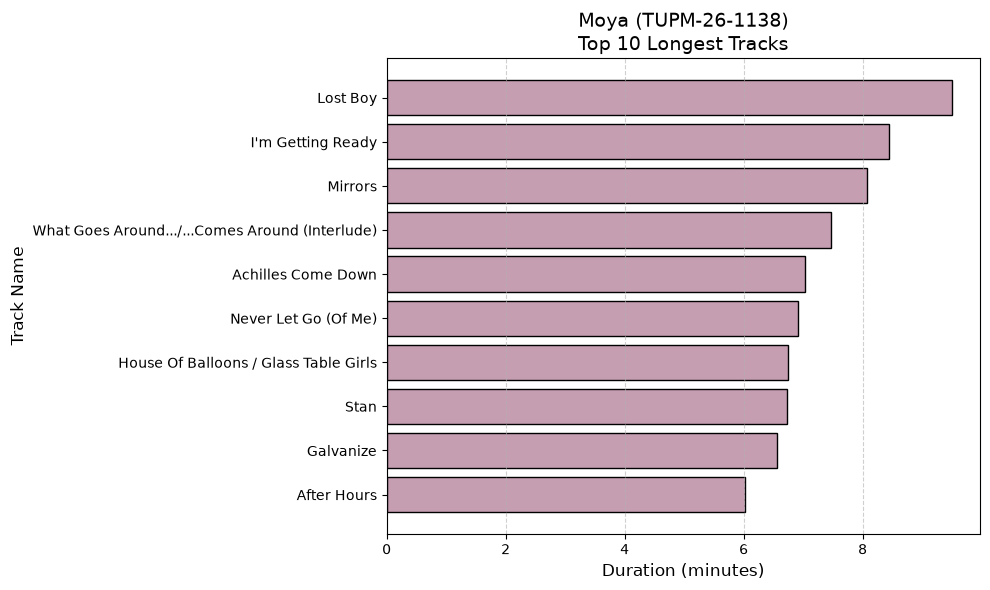

In [2]:
# Setup + Appendix E - Exercise 1: Identify Longest Tracks
import pandas as pd
import matplotlib.pyplot as plt

# Load and clean dataset
df = pd.read_csv("spotify_top_1000_tracks.csv", encoding="utf-8")
df['track_name'] = df['track_name'].str.strip()
df['artist'] = df['artist'].str.strip()
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df['year'] = df['release_date'].dt.year.fillna(0).astype(int)
df = df.drop_duplicates(subset=['track_name', 'artist'], keep='first')

# Student personalization
student_name = "Moya"
student_id = "TUPM-26-1138"
id_num = int(student_id[-3:])
color_bar = f"#{(id_num*7)%256:02x}{(id_num*3)%256:02x}{(id_num*5)%256:02x}"

# Sort by duration_min descending and select top 10
top10_longest = df.sort_values(by='duration_min', ascending=False).head(10)

# Output 1: Table showing track name, artist, and duration
print(f"Top 10 Longest Tracks - {student_name} ({student_id})")
display(top10_longest[['track_name', 'artist', 'duration_min']].reset_index(drop=True))

# Output 2: Horizontal bar chart
plt.figure(figsize=(10, 6))
plt.barh(top10_longest['track_name'], top10_longest['duration_min'], color=color_bar, edgecolor='black')
plt.gca().invert_yaxis()
plt.title(f"{student_name} ({student_id})\nTop 10 Longest Tracks", fontsize=14)
plt.xlabel("Duration (minutes)", fontsize=12)
plt.ylabel("Track Name", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

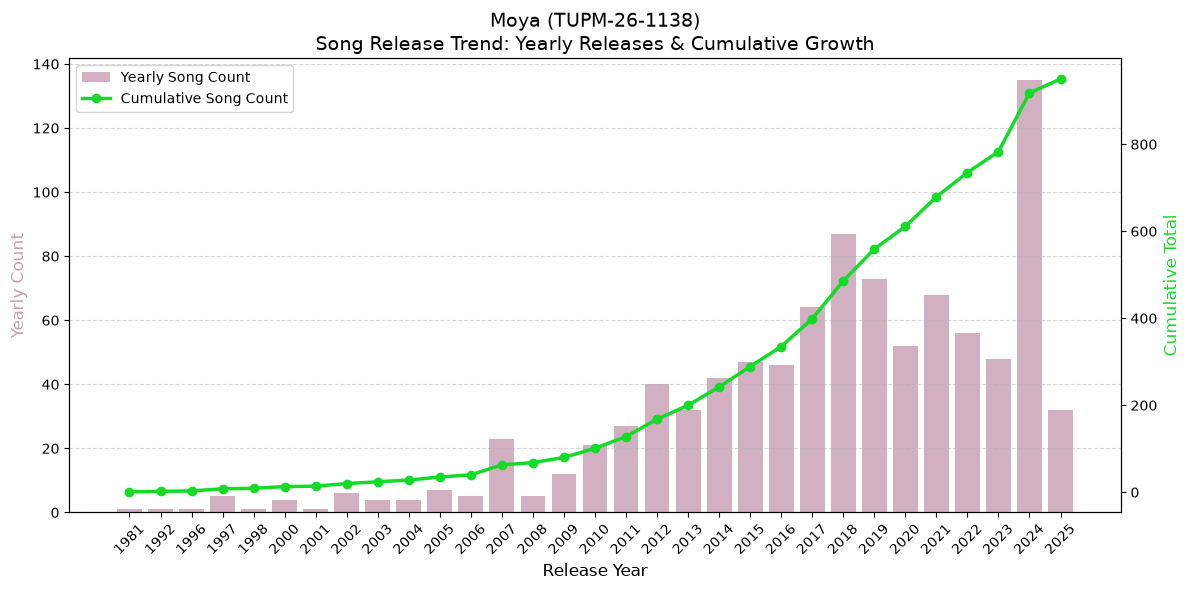

In [3]:
# Appendix E - Exercise 2: Song Release Trend
student_name = "Moya"
student_id = "TUPM-26-1138"
id_num = int(student_id[-3:])
color_bar = f"#{(id_num*7)%256:02x}{(id_num*3)%256:02x}{(id_num*5)%256:02x}"
color_line = f"#{(id_num*2)%256:02x}{(id_num*9)%256:02x}{(id_num*4)%256:02x}"

# Filter valid years (> 0), count songs per year, and compute cumulative sum
valid_years = df[df['year'] > 0]
yearly_counts = valid_years.groupby('year').size().sort_index()
cumulative_counts = yearly_counts.cumsum()

# Combined Bar + Line Chart
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.bar(yearly_counts.index.astype(str), yearly_counts.values, color=color_bar, alpha=0.8, label='Yearly Song Count')
ax1.set_xlabel("Release Year", fontsize=12)
ax1.set_ylabel("Yearly Count", color=color_bar, fontsize=12)
ax1.tick_params(axis='x', rotation=45)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

ax2 = ax1.twinx()
ax2.plot(yearly_counts.index.astype(str), cumulative_counts.values, color=color_line, marker='o', linewidth=2.5, label='Cumulative Song Count')
ax2.set_ylabel("Cumulative Total", color=color_line, fontsize=12)

# Combined Legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.title(f"{student_name} ({student_id})\nSong Release Trend: Yearly Releases & Cumulative Growth", fontsize=14)
plt.tight_layout()
plt.show()

In [4]:
# Appendix E - Exercise 3: Animated Density Map of Duration vs Popularity
import os
import webbrowser
from matplotlib.animation import FuncAnimation, PillowWriter

student_name = "Moya"
student_id = "TUPM-26-1138"
cmap_color = "viridis"

df_anim_hex = df[df['year'] > 0].dropna(subset=['duration_min', 'popularity', 'year']).copy()
years = sorted(df_anim_hex['year'].unique())

fig, ax = plt.subplots(figsize=(10, 6))
x_min, x_max = df_anim_hex['duration_min'].min() - 0.2, df_anim_hex['duration_min'].max() + 0.2
y_min, y_max = -5, 105

# Initial colorbar setup using full dataset bounds
hb_init = ax.hexbin(df_anim_hex['duration_min'], df_anim_hex['popularity'], gridsize=20, cmap=cmap_color, extent=[x_min, x_max, y_min, y_max])
cb = fig.colorbar(hb_init, ax=ax, label='Track Count')

def animate_hex(frame_idx):
    ax.clear()
    current_year = years[frame_idx]
    subset = df_anim_hex[df_anim_hex['year'] <= current_year]
    
    ax.hexbin(
        subset['duration_min'],
        subset['popularity'],
        gridsize=20,
        cmap=cmap_color,
        mincnt=1,
        extent=[x_min, x_max, y_min, y_max]
    )
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_title(f"{student_name} ({student_id}) — Up to Year {current_year}\nAnimated Density Map: Duration vs Popularity", fontsize=13)
    ax.set_xlabel("Duration (minutes)", fontsize=11)
    ax.set_ylabel("Popularity Score (0-100)", fontsize=11)
    ax.grid(True, linestyle='--', alpha=0.4)

ani_hex = FuncAnimation(fig, animate_hex, frames=len(years), interval=250, repeat=False)

hex_gif_path = os.path.abspath("duration_popularity_hexbin.gif")
ani_hex.save(hex_gif_path, writer=PillowWriter(fps=4))
print(f"Animated Hexbin GIF saved successfully at: {hex_gif_path}")

webbrowser.open(f"file://{hex_gif_path}")
plt.close(fig)

Animated Hexbin GIF saved successfully at: c:\Users\ADMIN\Lab8_Data_Visualization_Moya\duration_popularity_hexbin.gif
